# Breast cancer on ultrasound: classification and segmentation

Two models trained on breast ultrasound images, both using a ResNet-34 pretrained on ImageNet:
- a classifier: normal, benign or malignant
- a U-Net that segments the lesion

This is the second version. The first one trained on BUSI ([Al-Dhabyani et al., 2020](https://doi.org/10.1016/j.dib.2019.104863)), 780 images from 600 women scanned in 2018 at Baheya Hospital in Cairo. 155 of those images are duplicates ([Pawłowska et al., 2023](https://doi.org/10.1016/j.dib.2023.109247)) and my own check only found 18 pairs, so copies of training images could still end up in the test set and the v1 scores are probably too high. This time I train on the Curated BUSI ([Aumente-Maestro et al., 2025](https://doi.org/10.1016/j.cmpb.2024.108540)). Its authors removed the duplicates and the problematic cases with an automatic search followed by a manual review, and 450 images are left.

Instead of one train / val / test split I use 5-fold cross-validation, so every image gets tested once by a model that never saw it.

To see how the models behave on data from somewhere else, I also test them on BUS-BRA ([Gómez-Flores et al., 2024](https://doi.org/10.1002/mp.16812)), 1875 images from 1064 patients in Brazil, all biopsy-proven. It's never used for training. In v1 the scores dropped a lot there, so this version uses stronger augmentation and averages the 5 fold models on BUS-BRA.

Research / learning project, not for medical use.

## 1. Setup

In [1]:
import hashlib
import random
import time
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from scipy import ndimage
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
                             classification_report, f1_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, train_test_split
from torch.utils.data import DataLoader, Dataset
from torchvision import tv_tensors
from torchvision.models import ResNet34_Weights, resnet34
from torchvision.transforms import v2 as T

In [2]:
SEED = 42
IMG_SIZE = 256   # has to be a multiple of 32 for the unet
BATCH_SIZE = 16
EPOCHS_CLS = 40
EPOCHS_SEG = 50
PATIENCE = 10    # early stopping
LR = 3e-4
PRETRAINED = True

N_FOLDS = 5
VAL_SHARE = 0.15      # part of the training folds kept aside for early stopping
TARGET_SENS = 0.9     # malignant sensitivity used to set the decision threshold (section 5)

DUP_THRESHOLD = 0.9   # see section 3
MIN_LESION_PX = 50    # predicted blobs smaller than this are removed

RUN_EXTERNAL_TEST = True
# set these if you already have the datasets somewhere
BUSI_DIR = None
BUSBRA_DIR = None

DATA_DIR = Path("data")
MODEL_DIR = Path("models")
DATA_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

CLASSES = ["normal", "benign", "malignant"]

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
else:
    DEVICE = torch.device("cpu")
USE_AMP = DEVICE.type == "cuda"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)
print("torch", torch.__version__, "on", DEVICE)

torch 2.11.0+cu130 on cuda


## 2. Loading the curated BUSI

Downloaded from [Zenodo](https://doi.org/10.5281/zenodo.19047974) (57 MB, CC BY 4.0). The images are grayscale and 512x512, all in one folder with the class in the file name, e.g. `benign_id_100.png`, and the masks are in another folder (`benign_id_100_mask.png`). The ids are the ones of the original BUSI. When an image has two lesions, both are in the same mask. The normal images have an empty mask.

In [3]:
BUSI_URL = "https://zenodo.org/records/19047974/files/Curated%20BUSI.zip?download=1"
BUSI_MD5 = "88adb701f5cb7a3313033816e50049d2"


def download(url, md5, zip_path):
    # download the zip once, check it, then extract it into DATA_DIR
    if not zip_path.exists():
        print(f"downloading {zip_path.name}...")
        urllib.request.urlretrieve(url, zip_path)
    found = hashlib.md5(zip_path.read_bytes()).hexdigest()
    if found != md5:
        raise ValueError(f"wrong checksum for {zip_path} ({found}), delete it and run again")
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_DIR)


def get_busi():
    if BUSI_DIR is not None:
        return next(Path(BUSI_DIR).rglob("images")).parent
    root = DATA_DIR / "Curated BUSI"
    if not (root / "images").is_dir():
        download(BUSI_URL, BUSI_MD5, DATA_DIR / "CuratedBUSI.zip")   # the zip contains a "Curated BUSI/" folder
    return root


busi_root = get_busi()
print(busi_root)

downloading CuratedBUSI.zip...
data/Curated BUSI


In [4]:
rows = []
for label in CLASSES:
    for f in sorted((busi_root / "images").glob(f"{label}_id_*.png")):
        mask = busi_root / "masks" / f"{f.stem}_mask.png"
        rows.append({"name": f.name, "label": label, "image": f, "masks": [mask]})
df = pd.DataFrame(rows)
df["y"] = df["label"].map(CLASSES.index)

print(len(df), "images")
print(df["label"].value_counts()[CLASSES].to_string())

450 images
label
normal        64
benign       222
malignant    164


In [5]:
def load_gray(path):
    return np.array(Image.open(path).convert("L"))


def pad_resize(arr, size, nearest=False):
    # pad to a square first, otherwise the resize squashes the lesion
    h, w = arr.shape
    s = max(h, w)
    out = np.zeros((s, s), dtype=arr.dtype)
    top, left = (s - h) // 2, (s - w) // 2
    out[top:top + h, left:left + w] = arr
    resample = Image.Resampling.NEAREST if nearest else Image.Resampling.BILINEAR
    return np.array(Image.fromarray(out).resize((size, size), resample))


def load_case(image_path, mask_paths, size=IMG_SIZE):
    img = load_gray(image_path)
    mask = np.zeros(img.shape, dtype=np.uint8)
    for p in mask_paths:
        m = load_gray(p)
        if m.shape != img.shape:   # just in case a mask doesn't have the image size
            m = np.array(Image.fromarray(m).resize(img.shape[::-1], Image.Resampling.NEAREST))
        mask |= (m > 127).astype(np.uint8)
    return pad_resize(img, size), pad_resize(mask, size, nearest=True).astype(bool)


images, masks = [], []
for r in df.itertuples():
    img, mask = load_case(r.image, r.masks)
    images.append(img)
    masks.append(mask)
images, masks = np.stack(images), np.stack(masks)
print(images.shape, masks.shape)

(450, 256, 256) (450, 256, 256)


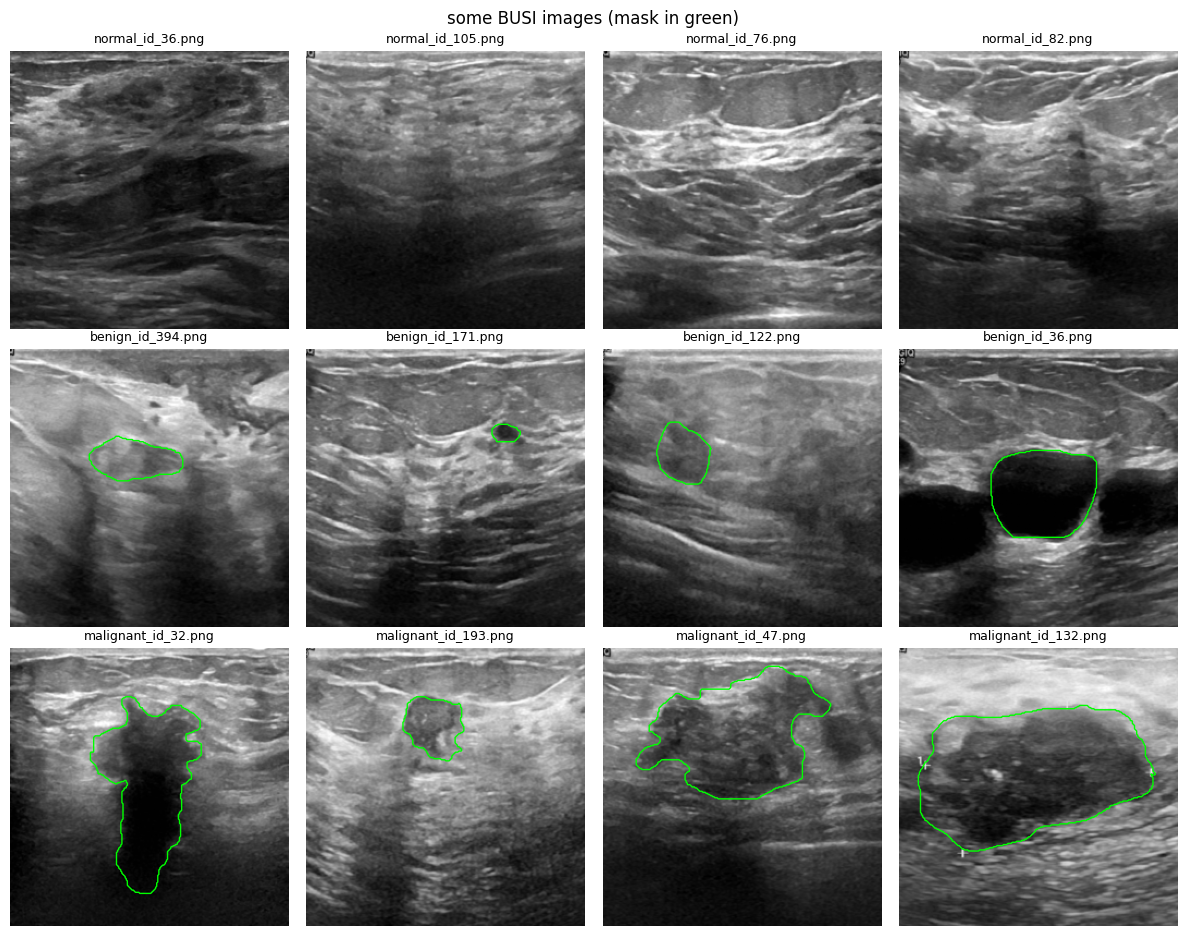

In [6]:
def show(ax, img, gt=None, pred=None, title=""):
    ax.imshow(img, cmap="gray")
    if gt is not None and gt.any():
        ax.contour(gt, levels=[0.5], colors="lime", linewidths=1)
    if pred is not None and pred.any():
        ax.contour(pred, levels=[0.5], colors="red", linewidths=1)
    ax.set_title(title, fontsize=9)
    ax.axis("off")


fig, axes = plt.subplots(3, 4, figsize=(12, 9.5))
for row, label in zip(axes, CLASSES):
    idx = rng.choice(np.flatnonzero(df["label"] == label), 4, replace=False)
    for ax, i in zip(row, idx):
        show(ax, images[i], masks[i], title=df.at[i, "name"])
plt.suptitle("some BUSI images (mask in green)")
plt.tight_layout()
plt.show()

## 3. Checking for duplicates

The curated set shouldn't have duplicates left, but I still run the check I wrote for v1 as a sanity check. Correlating raw pixels isn't a good idea here because all ultrasound images share the same overall look (bright near the skin, darker with depth), so two different scans can still correlate a lot. Each image gets a "fingerprint" instead:
1. resize to 128x128
2. subtract a blurred copy of itself, which only keeps the fine texture (speckle, edges)
3. subtract the mean fingerprint of the dataset, to remove what all scans have in common

Two images whose fingerprints correlate above `DUP_THRESHOLD` are counted as the same image. On the original BUSI this found 18 pairs. Here nothing gets removed, I only count what it still finds. Cropped or zoomed copies won't be caught by this.

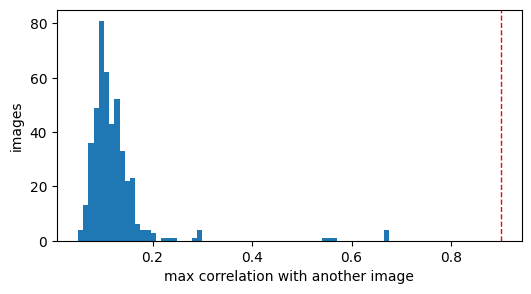

0 pairs above the threshold, highest correlation 0.675


In [7]:
def fingerprint(path, size=128):
    img = Image.open(path).convert("L").resize((size, size), Image.Resampling.BOX)
    x = torch.from_numpy(np.asarray(img, dtype=np.float32))[None, None]
    blurred = F.avg_pool2d(x, 9, stride=1, padding=4, count_include_pad=False)
    return (x - blurred).flatten()


fps = torch.stack([fingerprint(p) for p in df["image"]])
fps = fps - fps.mean(0)
fps = fps - fps.mean(1, keepdim=True)
fps = F.normalize(fps, dim=1)
corr = (fps @ fps.T).numpy()   # pearson correlation for every pair
np.fill_diagonal(corr, -1)

plt.figure(figsize=(6, 3))
plt.hist(corr.max(1), bins=60)
plt.axvline(DUP_THRESHOLD, color="red", ls="--", lw=1)
plt.xlabel("max correlation with another image")
plt.ylabel("images")
plt.show()

pairs = np.argwhere(np.triu(corr, k=1) > DUP_THRESHOLD)
print(f"{len(pairs)} pairs above the threshold, highest correlation {corr.max():.3f}")

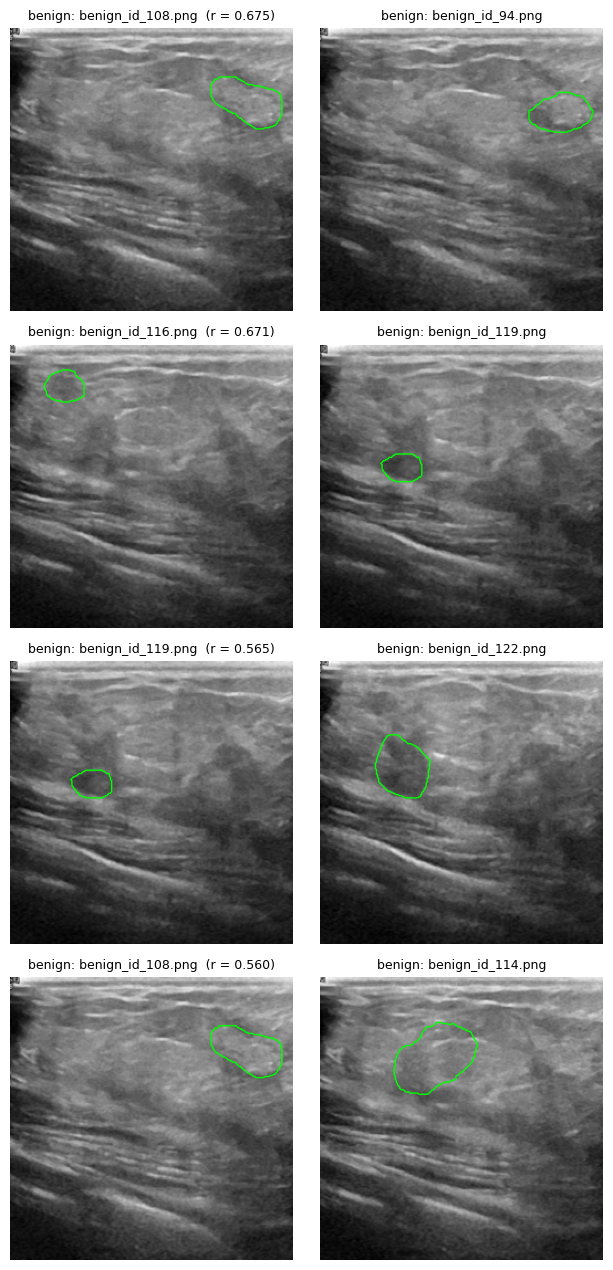

In [8]:
# closest pairs, even under the threshold
top = np.argsort(np.triu(corr, k=1), axis=None)[::-1][:4]
closest = np.column_stack(np.unravel_index(top, corr.shape))
fig, axes = plt.subplots(len(closest), 2, figsize=(6.5, 3.2 * len(closest)))
for (a, b), row in zip(closest, axes):
    show(row[0], images[a], masks[a], title=f"{df.at[a, 'label']}: {df.at[a, 'name']}  (r = {corr[a, b]:.3f})")
    show(row[1], images[b], masks[b], title=f"{df.at[b, 'label']}: {df.at[b, 'name']}")
plt.tight_layout()
plt.show()

Then 5-fold cross-validation, stratified by class. Each fold is the test set once, for models trained on the other 4 folds. A share of those 4 folds (`VAL_SHARE`, also stratified) is kept aside to choose the best epoch. In the end every image has a prediction from a model that never trained on it, so the in-domain results below use all 450 images instead of a small test split.

In [9]:
y_all = df["y"].values
df["fold"] = -1
folds = StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED)
for k, (_, test_idx) in enumerate(folds.split(df, y_all)):
    df.loc[test_idx, "fold"] = k


def fold_split(k):
    # train / val / test indices of fold k
    test_idx = np.flatnonzero(df["fold"] == k)
    rest = np.flatnonzero(df["fold"] != k)
    train_idx, val_idx = train_test_split(rest, test_size=VAL_SHARE, stratify=y_all[rest], random_state=SEED)
    return train_idx, val_idx, test_idx


df[["name", "label", "fold"]].to_csv(DATA_DIR / "busi_folds.csv", index=False)
pd.crosstab(df["label"], df["fold"]).reindex(CLASSES)

fold,0,1,2,3,4
label,,,,,
normal,13,13,13,13,12
benign,45,44,44,44,45
malignant,32,33,33,33,33


## 4. Dataset and augmentation

The image and its mask get the same random geometric transform so they stay aligned: sometimes a zoom out that shrinks the image inside a black frame, a random crop (70 to 100% of the area, aspect ratio between 0.8 and 1.25) resized back to `IMG_SIZE`, a small rotation and a horizontal flip. No vertical flip since the skin is always at the top on ultrasound. After that only the image changes: brightness, contrast, gamma, sometimes a light blur, and multiplicative noise as a rough imitation of speckle.

It's stronger than in v1 because the models lost a lot on BUS-BRA. Another hospital means other machines and other settings, and that's what these changes try to imitate. The aspect ratio part is there because the curated images were all brought to 512x512 while the BUS-BRA ones keep their own proportions (I pad them to a square), so a lesion can look a bit wider or narrower depending on the dataset. The zoom out has to do with the padding too. Most BUS-BRA images are taller than wide, so they get black bars on the sides, while the curated images fill the whole frame. Without it the models would almost never see a black border during training.

At test time both models also see each image flipped horizontally, and I average the two predictions.

The images are grayscale, so they're copied to 3 channels for the ImageNet weights.

In [10]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)   # imagenet stats
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def gamma_and_noise(img):
    # random gamma, then multiplicative noise as a rough imitation of speckle
    x = (img / 255) ** torch.empty(1).uniform_(0.7, 1.4)
    x = x * (1 + 0.15 * torch.rand(1) * torch.randn_like(x))
    return (x.clamp(0, 1) * 255).round().to(torch.uint8)


augment = T.Compose([
    T.RandomZoomOut(side_range=(1, 1.4), p=0.3),   # black borders, like a padded BUS-BRA image
    T.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1), ratio=(0.8, 1.25)),
    T.RandomRotation(10),
    T.RandomHorizontalFlip(),
    # transforms.v2 leaves the Mask untouched for the ones below
    T.ColorJitter(brightness=0.2, contrast=0.2),
    T.RandomApply([T.GaussianBlur(5, sigma=(0.1, 1))], p=0.3),
    T.Lambda(gamma_and_noise, tv_tensors.Image),
])


def to_input(img):
    # uint8 gray image -> normalized 3 channel float tensor
    x = torch.as_tensor(img).float() / 255
    if x.ndim == 2:
        x = x[None]
    return (x.expand(3, -1, -1) - MEAN) / STD


class BreastUltrasound(Dataset):
    def __init__(self, images, masks, labels, train=False):
        self.images = images
        self.masks = masks
        self.labels = labels
        self.train = train

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        img = tv_tensors.Image(torch.from_numpy(self.images[i])[None])
        mask = tv_tensors.Mask(torch.from_numpy(self.masks[i])[None].to(torch.uint8))
        if self.train:
            img, mask = augment(img, mask)
        x = to_input(img.as_subclass(torch.Tensor))
        return x, mask.as_subclass(torch.Tensor).float(), int(self.labels[i])


# no worker processes: everything is already in RAM, and workers can't pickle a Dataset
# defined in a notebook on mac/windows or python >= 3.14 (spawn / forkserver)
def make_loader(idx, train=False):
    ds = BreastUltrasound(images[idx], masks[idx], y_all[idx], train)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=train, drop_last=train,
                      pin_memory=DEVICE.type == "cuda")

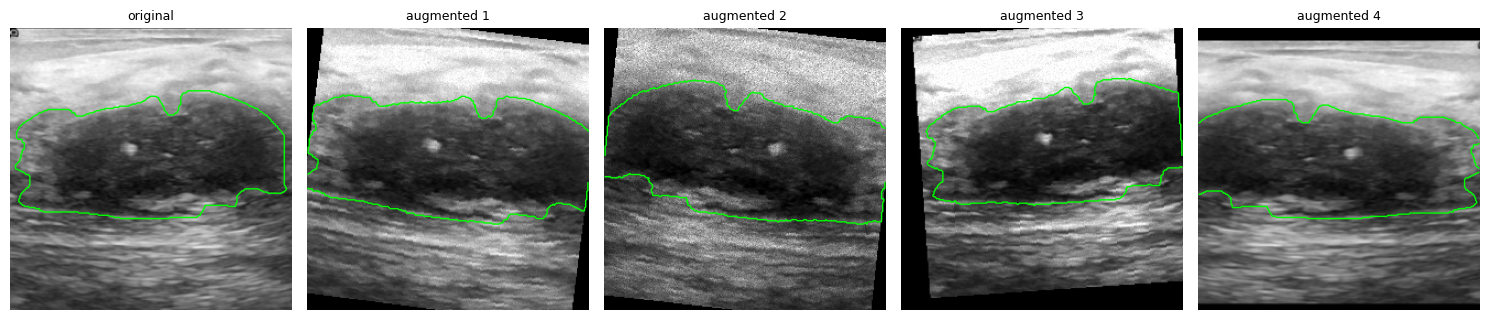

In [11]:
# what the augmentation looks like on one image
i = np.flatnonzero(df["label"] == "malignant")[0]
one = BreastUltrasound(images[[i]], masks[[i]], [2], train=True)

fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))
show(axes[0], images[i], masks[i], title="original")
for k in range(1, 5):
    x, m, _ = one[0]
    show(axes[k], (x * STD + MEAN)[0].clamp(0, 1), m[0], title=f"augmented {k}")
plt.tight_layout()
plt.show()

Training loop used for both models: AdamW with a cosine schedule, mixed precision on GPU, early stopping on the validation score, and at the end it reloads the weights from the best epoch. It runs once per fold, and each fold starts from its own fixed seed. A fold only trains on about 300 images (532 in v1) and the augmentation is stronger, so I give it a few more epochs and a bit more patience than in v1.

In [12]:
def autocast():
    return torch.autocast(device_type="cuda" if USE_AMP else "cpu", enabled=USE_AMP)


def train_model(model, train_loader, val_loader, loss_fn, score_fn, epochs, name):
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.amp.GradScaler(enabled=USE_AMP)
    best_score, best_state, bad_epochs = -1, None, 0
    history = []
    t0 = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        losses = []
        for x, m, y in train_loader:
            x, m, y = x.to(DEVICE), m.to(DEVICE), y.to(DEVICE)
            with autocast():
                out = model(x)
            loss = loss_fn(out.float(), m, y)
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            losses.append(loss.item())
        sched.step()

        score = score_fn(model, val_loader)
        history.append({"epoch": epoch, "train loss": np.mean(losses), "val score": score})
        print(f"epoch {epoch:2d}  loss {np.mean(losses):.3f}  val {score:.3f}")

        if score > best_score:
            best_score, bad_epochs = score, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs == PATIENCE:
                print("early stop")
                break

    model.load_state_dict(best_state)
    torch.save(best_state, MODEL_DIR / f"{name}.pt")
    print(f"best val {best_score:.3f} ({time.time() - t0:.0f}s), saved to {MODEL_DIR / name}.pt")
    return pd.DataFrame(history)


def plot_history(histories, score_name):
    # one line per fold
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.2))
    for k, history in enumerate(histories):
        ax1.plot(history["epoch"], history["train loss"], label=f"fold {k}")
        ax2.plot(history["epoch"], history["val score"])
    ax1.set_title("train loss")
    ax1.legend(fontsize=8)
    ax2.set_title("val " + score_name)
    for ax in (ax1, ax2):
        ax.set_xlabel("epoch")
    plt.tight_layout()
    plt.show()


def bootstrap_ci(metric, y, p, groups=None, n=1000):
    # 95% CI from n resamples of the test set.
    # with groups (patient ids) whole patients are resampled instead of single images
    r = np.random.default_rng(SEED)
    if groups is None:
        groups = np.arange(len(y))
    _, g = np.unique(groups, return_inverse=True)
    members = [np.flatnonzero(g == k) for k in range(g.max() + 1)]
    vals = []
    for _ in range(n):
        picked = r.integers(0, len(members), len(members))
        i = np.concatenate([members[k] for k in picked])
        if len(np.unique(y[i])) == len(np.unique(y)):   # skip resamples where a class is missing
            vals.append(metric(y[i], p[i]))
    return np.percentile(vals, [2.5, 97.5])

## 5. Classifier

ResNet-34 with a new 3-class head, one per fold. Benign is about half of the images and normal only 14%, so the loss uses class weights (inverse frequency), otherwise the model can mostly ignore normal and malignant. The best epoch is the one with the best macro-F1 on validation.

fold 0
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 180MB/s]


epoch  1  loss 1.141  val 0.524
epoch  2  loss 0.985  val 0.647
epoch  3  loss 0.807  val 0.716
epoch  4  loss 0.659  val 0.701
epoch  5  loss 0.609  val 0.742
epoch  6  loss 0.623  val 0.831
epoch  7  loss 0.578  val 0.768
epoch  8  loss 0.552  val 0.773
epoch  9  loss 0.472  val 0.857
epoch 10  loss 0.528  val 0.845
epoch 11  loss 0.485  val 0.779
epoch 12  loss 0.405  val 0.832
epoch 13  loss 0.427  val 0.874
epoch 14  loss 0.443  val 0.734
epoch 15  loss 0.465  val 0.889
epoch 16  loss 0.404  val 0.882
epoch 17  loss 0.391  val 0.788
epoch 18  loss 0.364  val 0.859
epoch 19  loss 0.333  val 0.778
epoch 20  loss 0.317  val 0.824
epoch 21  loss 0.345  val 0.884
epoch 22  loss 0.360  val 0.881
epoch 23  loss 0.332  val 0.838
epoch 24  loss 0.289  val 0.858
epoch 25  loss 0.284  val 0.882
early stop
best val 0.889 (91s), saved to models/classifier_fold0.pt
fold 1
epoch  1  loss 1.052  val 0.217
epoch  2  loss 0.920  val 0.280
epoch  3  loss 0.737  val 0.700
epoch  4  loss 0.779  val 0.

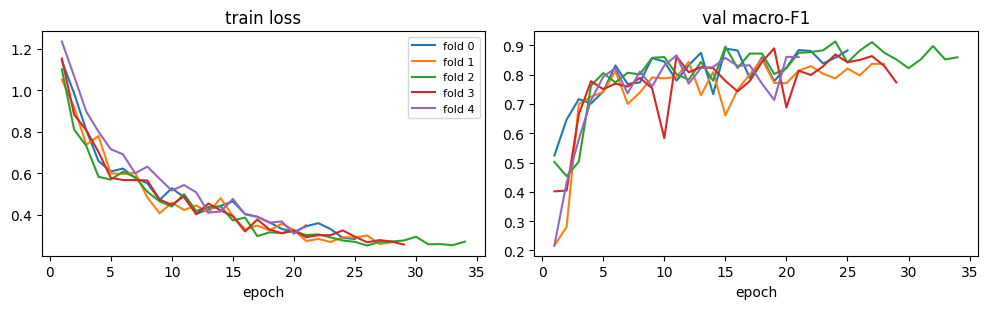

In [13]:
def resnet34_backbone():
    weights = ResNet34_Weights.IMAGENET1K_V1 if PRETRAINED else None
    return resnet34(weights=weights)


@torch.no_grad()
def predict_probs(models, loader):
    # softmax averaged over the models and over each image and its horizontal flip
    for model in models:
        model.eval()
    probs, ys = [], []
    for x, _, y in loader:
        x = x.to(DEVICE)
        with autocast():
            p = sum(model(x).float().softmax(1) + model(x.flip(-1)).float().softmax(1) for model in models)
        probs.append(p.cpu() / (2 * len(models)))
        ys.append(y)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()


def val_f1(model, loader):
    p, y = predict_probs([model], loader)
    return f1_score(y, p.argmax(1), average="macro")


classifiers, cls_histories = [], []
p_oof = np.zeros((len(df), len(CLASSES)))
p_val, y_val = [], []   # validation predictions of each fold, used to set the threshold
for k in range(N_FOLDS):
    print(f"fold {k}")
    torch.manual_seed(SEED + k)
    train_idx, val_idx, test_idx = fold_split(k)
    counts = np.bincount(y_all[train_idx], minlength=len(CLASSES))
    class_w = torch.tensor(len(train_idx) / (len(CLASSES) * counts), dtype=torch.float32)
    criterion = nn.CrossEntropyLoss(weight=class_w.to(DEVICE), label_smoothing=0.05)

    model = resnet34_backbone()
    model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, len(CLASSES)))
    model = model.to(DEVICE)
    val_loader = make_loader(val_idx)
    history = train_model(model, make_loader(train_idx, train=True), val_loader,
                          lambda out, m, y: criterion(out, y), val_f1, EPOCHS_CLS, f"classifier_fold{k}")
    p_val.append(predict_probs([model], val_loader)[0])
    y_val.append(y_all[val_idx])
    p_oof[test_idx] = predict_probs([model], make_loader(test_idx))[0]
    classifiers.append(model)
    cls_histories.append(history)

p_val, y_val = np.concatenate(p_val), np.concatenate(y_val)
plot_history(cls_histories, "macro-F1")

### Results, out of fold

Every image is predicted by the classifier of the fold where it was in the test set. Malignant sensitivity = share of malignant images predicted malignant, malignant specificity = share of the other images not predicted malignant, benign specificity = share of benign images not predicted malignant. The 95% CIs come from 1000 bootstrap resamples of the 450 images.

A missed cancer is worse than a false alarm, so I also try a threshold on P(malignant) instead of taking the most likely class. It's set on the validation images of the folds so that it finds 90% of their malignant images (`TARGET_SENS`), then used as it is on the test folds and on BUS-BRA.

In [14]:
_, tpr, thresholds = roc_curve(y_val == 2, p_val[:, 2], drop_intermediate=False)
threshold = thresholds[np.argmax(tpr >= TARGET_SENS)]   # the highest one that reaches the target
print(f"threshold on P(malignant): {threshold:.3f}")

metrics = {
    "accuracy": lambda y, p: accuracy_score(y, p.argmax(1)),
    "balanced accuracy": lambda y, p: balanced_accuracy_score(y, p.argmax(1)),
    "macro-F1": lambda y, p: f1_score(y, p.argmax(1), average="macro"),
    "ROC-AUC (one vs rest)": lambda y, p: roc_auc_score(y, p, multi_class="ovr"),
    "malignant sensitivity": lambda y, p: np.mean(p[y == 2].argmax(1) == 2),
    "malignant specificity": lambda y, p: np.mean(p[y != 2].argmax(1) != 2),
    "malignant sensitivity at threshold": lambda y, p: np.mean(p[y == 2, 2] >= threshold),
    "benign specificity at threshold": lambda y, p: np.mean(p[y == 1, 2] < threshold),
}
rows = []
for name, f in metrics.items():
    lo, hi = bootstrap_ci(f, y_all, p_oof)
    rows.append({"metric": name, "value": round(f(y_all, p_oof), 3), "95% CI": f"[{lo:.3f}, {hi:.3f}]"})
cls_results = pd.DataFrame(rows).set_index("metric")
cls_results

threshold on P(malignant): 0.213


,value,95% CI
metric,,
accuracy,0.829,"[0.793, 0.860]"
balanced accuracy,0.843,"[0.808, 0.875]"
macro-F1,0.819,"[0.778, 0.852]"
ROC-AUC (one vs rest),0.939,"[0.918, 0.956]"
malignant sensitivity,0.823,"[0.766, 0.880]"
malignant specificity,0.895,"[0.860, 0.931]"
malignant sensitivity at threshold,0.890,"[0.840, 0.930]"
benign specificity at threshold,0.815,"[0.765, 0.869]"


              precision    recall  f1-score   support

      normal      0.704     0.891     0.786        64
      benign      0.887     0.815     0.850       222
   malignant      0.818     0.823     0.821       164

    accuracy                          0.829       450
   macro avg      0.803     0.843     0.819       450
weighted avg      0.836     0.829     0.830       450



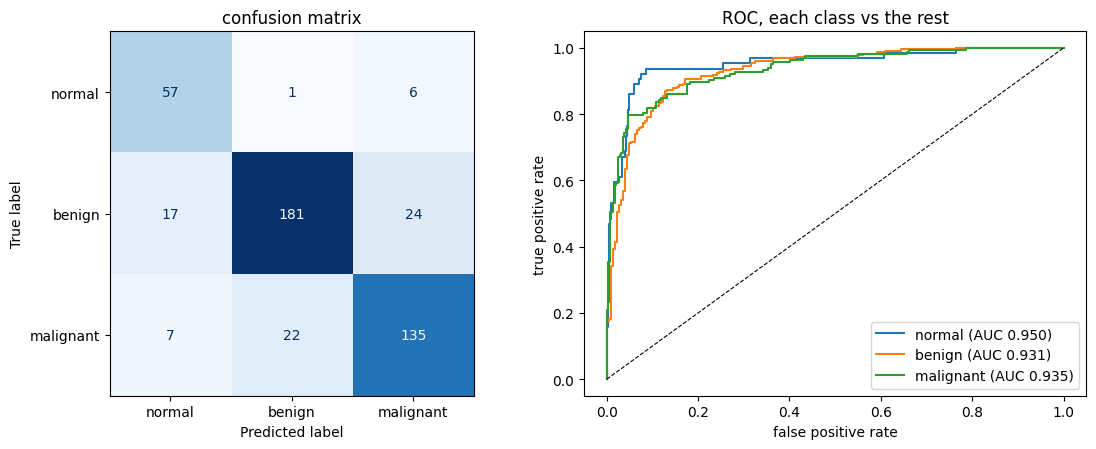

In [15]:
pred_oof = p_oof.argmax(1)
print(classification_report(y_all, pred_oof, target_names=CLASSES, digits=3, zero_division=0))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.6))
ConfusionMatrixDisplay.from_predictions(y_all, pred_oof, display_labels=CLASSES, cmap="Blues",
                                        colorbar=False, ax=ax1)
ax1.set_title("confusion matrix")
for k, c in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(y_all == k, p_oof[:, k])
    auc = roc_auc_score(y_all == k, p_oof[:, k])
    ax2.plot(fpr, tpr, label=f"{c} (AUC {auc:.3f})")
ax2.plot([0, 1], [0, 1], "k--", lw=0.8)
ax2.set_xlabel("false positive rate")
ax2.set_ylabel("true positive rate")
ax2.set_title("ROC, each class vs the rest")
ax2.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Grad-CAM

Grad-CAM ([Selvaraju et al., 2017](https://arxiv.org/abs/1610.02391)) shows which regions the prediction relies on. I use it as a sanity check: the heatmap should be on the lesion (green), not on the text and caliper marks that are still on some of the curated images. Each image goes through the classifier of its own test fold.

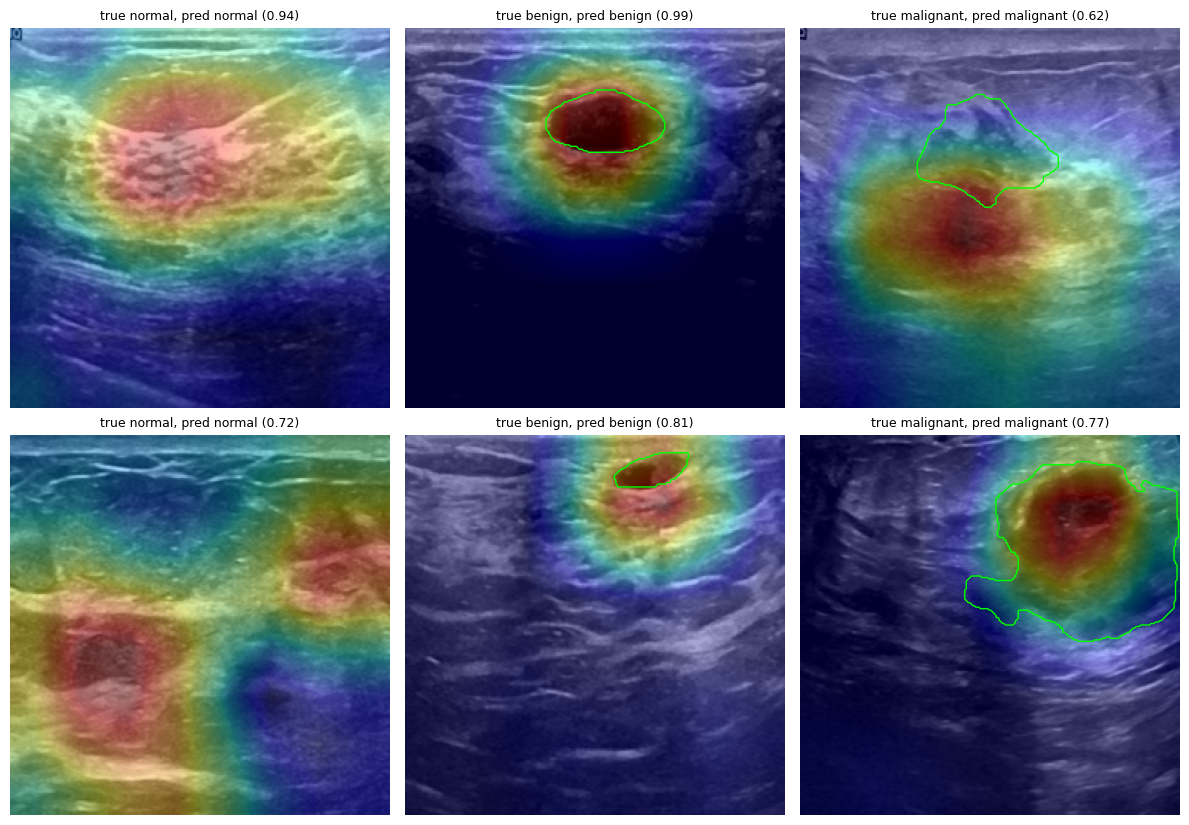

In [16]:
def grad_cam(model, x, layer):
    saved = {}

    def hook(module, inp, out):
        saved["act"] = out
        out.register_hook(lambda g: saved.update(grad=g))

    h = layer.register_forward_hook(hook)
    model.eval()
    try:
        logits = model(x[None].to(DEVICE))
    finally:
        h.remove()
    probs = logits.softmax(1)[0].detach().cpu().numpy()
    cls = int(probs.argmax())
    model.zero_grad()
    logits[0, cls].backward()

    w = saved["grad"].mean(dim=(2, 3), keepdim=True)   # one weight per channel
    cam = F.relu((w * saved["act"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = cam / (cam.max() + 1e-8)
    return cam.detach().cpu().numpy(), cls, probs


fig, axes = plt.subplots(2, 3, figsize=(12, 8.4))
for k in range(len(CLASSES)):
    ids = np.flatnonzero(y_all == k)
    for row, i in enumerate(rng.choice(ids, min(2, len(ids)), replace=False)):
        model = classifiers[df.at[i, "fold"]]   # the one that didn't train on this image
        cam, cls, probs = grad_cam(model, to_input(images[i]), model.layer4)
        ax = axes[row, k]
        ax.imshow(images[i], cmap="gray")
        ax.imshow(cam, cmap="jet", alpha=0.35)
        if masks[i].any():
            ax.contour(masks[i], levels=[0.5], colors="lime", linewidths=1)
        ax.set_title(f"true {CLASSES[k]}, pred {CLASSES[cls]} ({probs[cls]:.2f})", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. U-Net

U-Net ([Ronneberger et al., 2015](https://arxiv.org/abs/1505.04597)) where the encoder is the same pretrained ResNet-34. Again one per fold, with the same folds as the classifier. I train it on every image, normal ones included. Their mask is empty, so the model also learns to predict nothing when there's no lesion.

The loss is BCE + Dice. On validation I use the mean Dice over all images (an empty prediction on a normal image counts as 1). Blobs smaller than `MIN_LESION_PX` pixels are removed from the predictions.

fold 0
epoch  1  loss 1.410  val 0.205
epoch  2  loss 1.271  val 0.285
epoch  3  loss 1.234  val 0.559
epoch  4  loss 1.201  val 0.564
epoch  5  loss 1.179  val 0.619
epoch  6  loss 1.148  val 0.566
epoch  7  loss 1.128  val 0.581
epoch  8  loss 1.113  val 0.696
epoch  9  loss 1.093  val 0.620
epoch 10  loss 1.061  val 0.628
epoch 11  loss 1.058  val 0.660
epoch 12  loss 1.036  val 0.683
epoch 13  loss 1.023  val 0.573
epoch 14  loss 1.002  val 0.683
epoch 15  loss 0.986  val 0.730
epoch 16  loss 0.966  val 0.652
epoch 17  loss 0.956  val 0.691
epoch 18  loss 0.953  val 0.674
epoch 19  loss 0.920  val 0.698
epoch 20  loss 0.909  val 0.697
epoch 21  loss 0.901  val 0.661
epoch 22  loss 0.887  val 0.571
epoch 23  loss 0.880  val 0.662
epoch 24  loss 0.863  val 0.713
epoch 25  loss 0.853  val 0.674
early stop
best val 0.730 (137s), saved to models/unet_fold0.pt
fold 1
epoch  1  loss 1.373  val 0.325
epoch  2  loss 1.259  val 0.439
epoch  3  loss 1.199  val 0.561
epoch  4  loss 1.172  val 

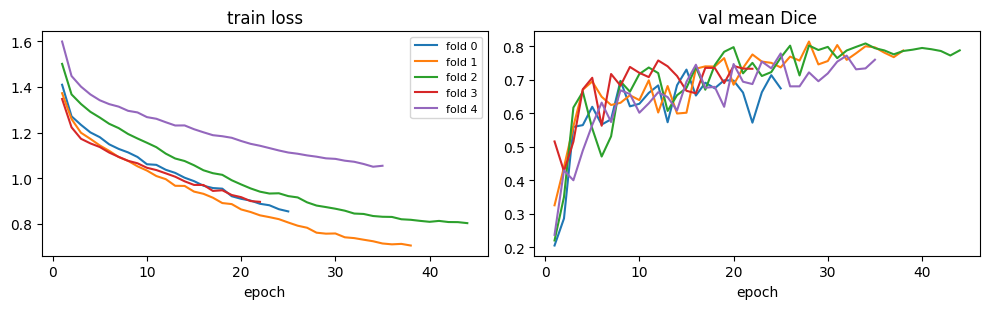

In [17]:
class Up(nn.Module):
    # upsample x2, concat the skip connection, then 2x conv-bn-relu
    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch + skip_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x, skip=None):
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        if skip is not None:
            x = torch.cat([x, skip], dim=1)
        return self.conv(x)


class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        r = resnet34_backbone()
        # encoder = resnet34 without the avgpool and fc
        self.stem = nn.Sequential(r.conv1, r.bn1, r.relu)   # 1/2
        self.pool = r.maxpool
        self.enc1 = r.layer1   # 1/4, 64 ch
        self.enc2 = r.layer2   # 1/8, 128 ch
        self.enc3 = r.layer3   # 1/16, 256 ch
        self.enc4 = r.layer4   # 1/32, 512 ch
        self.up4 = Up(512, 256, 256)
        self.up3 = Up(256, 128, 128)
        self.up2 = Up(128, 64, 64)
        self.up1 = Up(64, 64, 32)
        self.up0 = Up(32, 0, 16)   # back to full size, no skip at this level
        self.head = nn.Conv2d(16, 1, 1)

    def forward(self, x):
        s = self.stem(x)
        e1 = self.enc1(self.pool(s))
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)
        d = self.up4(e4, e3)
        d = self.up3(d, e2)
        d = self.up2(d, e1)
        d = self.up1(d, s)
        d = self.up0(d)
        return self.head(d)


def seg_loss(logits, target):
    # bce + soft dice, dice is computed per image then averaged
    prob = torch.sigmoid(logits)
    inter = (prob * target).sum((1, 2, 3))
    dice = (2 * inter + 1) / (prob.sum((1, 2, 3)) + target.sum((1, 2, 3)) + 1)
    return F.binary_cross_entropy_with_logits(logits, target) + (1 - dice).mean()


def clean_mask(mask):
    # remove small isolated blobs
    labels, n = ndimage.label(mask)
    if n == 0:
        return mask
    sizes = ndimage.sum(mask, labels, range(1, n + 1))
    keep = np.flatnonzero(sizes >= MIN_LESION_PX) + 1
    return np.isin(labels, keep)


@torch.no_grad()
def predict_masks(models, loader):
    # lesion probability averaged like in predict_probs, the flipped prediction is flipped back first
    for model in models:
        model.eval()
    preds = []
    for x, _, _ in loader:
        x = x.to(DEVICE)
        with autocast():
            prob = sum(torch.sigmoid(model(x).float()) + torch.sigmoid(model(x.flip(-1)).float()).flip(-1)
                       for model in models)
        prob = (prob[:, 0] / (2 * len(models))).cpu().numpy()
        preds += [clean_mask(p > 0.5) for p in prob]
    return np.stack(preds)


def dice_iou(pred, gt):
    inter = (pred & gt).sum()
    total = pred.sum() + gt.sum()
    if total == 0:   # normal image and nothing predicted
        return 1.0, 1.0
    return 2 * inter / total, inter / (total - inter)


def val_dice(model, loader):
    preds = predict_masks([model], loader)
    return np.mean([dice_iou(p, g)[0] for p, g in zip(preds, loader.dataset.masks)])


unets, seg_histories = [], []
pred_masks = np.zeros_like(masks)
for k in range(N_FOLDS):
    print(f"fold {k}")
    torch.manual_seed(SEED + k)
    train_idx, val_idx, test_idx = fold_split(k)
    model = UNet().to(DEVICE)
    history = train_model(model, make_loader(train_idx, train=True), make_loader(val_idx),
                          lambda out, m, y: seg_loss(out, m), val_dice, EPOCHS_SEG, f"unet_fold{k}")
    pred_masks[test_idx] = predict_masks([model], make_loader(test_idx))
    unets.append(model)
    seg_histories.append(history)

plot_history(seg_histories, "mean Dice")

### Results, out of fold

Dice and IoU are only computed on the images that have a lesion (1 = perfect overlap, 0 = none). For the normal images I just count how often the U-Net predicts a lesion that isn't there.

In [18]:
test_df = df.copy()   # every image was in the test set of one fold
scores = [dice_iou(p, g) for p, g in zip(pred_masks, masks)]
test_df["dice"] = [s[0] for s in scores]
test_df["iou"] = [s[1] for s in scores]
test_df["pred_px"] = pred_masks.sum((1, 2))
lesion = (test_df["label"] != "normal").values

rows = []
for name, sel in [("benign", test_df["label"] == "benign"),
                  ("malignant", test_df["label"] == "malignant"),
                  ("all lesions", lesion)]:
    d = test_df.loc[sel, "dice"].values
    lo, hi = bootstrap_ci(lambda y, p: p.mean(), test_df.loc[sel, "y"].values, d)
    rows.append({"lesions": name, "n": len(d), "mean Dice": round(d.mean(), 3),
                 "95% CI": f"[{lo:.3f}, {hi:.3f}]", "mean IoU": round(test_df.loc[sel, "iou"].mean(), 3)})
seg_results = pd.DataFrame(rows).set_index("lesions")

false_alarms = (test_df.loc[~lesion, "pred_px"] > 0).sum()
print(f"normal test images where the unet still predicts a lesion: {false_alarms}/{(~lesion).sum()}")
seg_results

normal test images where the unet still predicts a lesion: 21/64


,n,mean Dice,95% CI,mean IoU
lesions,,,,
benign,222,0.755,"[0.719, 0.788]",0.665
malignant,164,0.714,"[0.672, 0.754]",0.607
all lesions,386,0.738,"[0.711, 0.764]",0.641


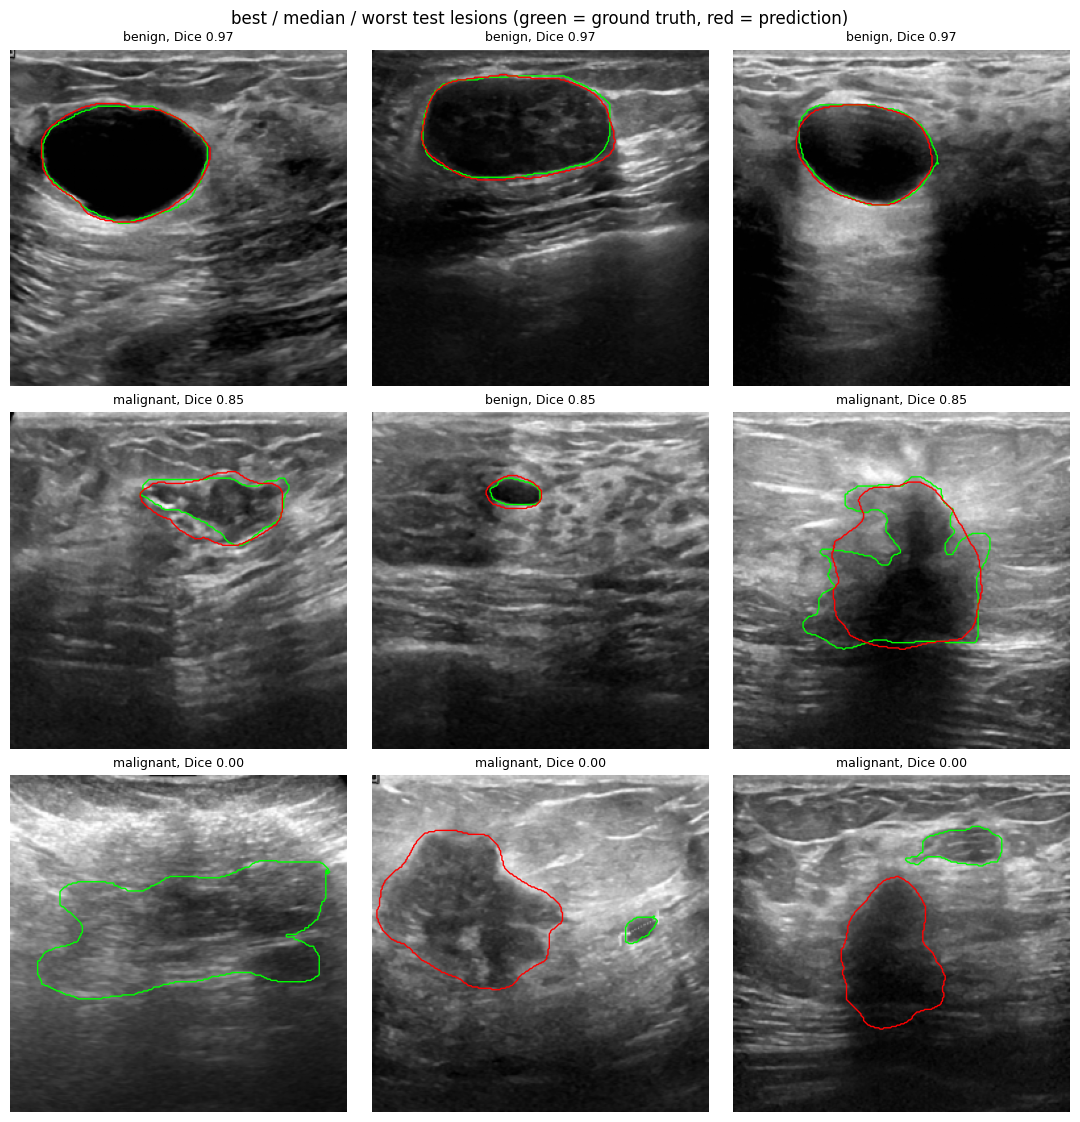

In [19]:
ranked = test_df[lesion].sort_values("dice", ascending=False)
mid = len(ranked) // 2
shown = pd.concat([ranked.head(3), ranked.iloc[max(mid - 1, 0):mid + 2], ranked.tail(3)])
shown = shown[~shown.index.duplicated()]   # can overlap if the test set is small

fig, axes = plt.subplots(3, 3, figsize=(11, 11.4))
for ax in axes.flat:
    ax.axis("off")
for ax, (i, r) in zip(axes.flat, shown.iterrows()):
    k = test_df.index.get_loc(i)
    show(ax, images[i], masks[i], pred_masks[k], title=f"{r['label']}, Dice {r['dice']:.2f}")
plt.suptitle("best / median / worst test lesions (green = ground truth, red = prediction)")
plt.tight_layout()
plt.show()

## 7. Both models on one image

`analyze` returns the class probabilities, the Grad-CAM map and the predicted mask for one preprocessed image, with the two models of one fold. Below, each image goes through the models of its own test fold. To try it on another scan: `analyze(pad_resize(load_gray("scan.png"), IMG_SIZE), 0)`.

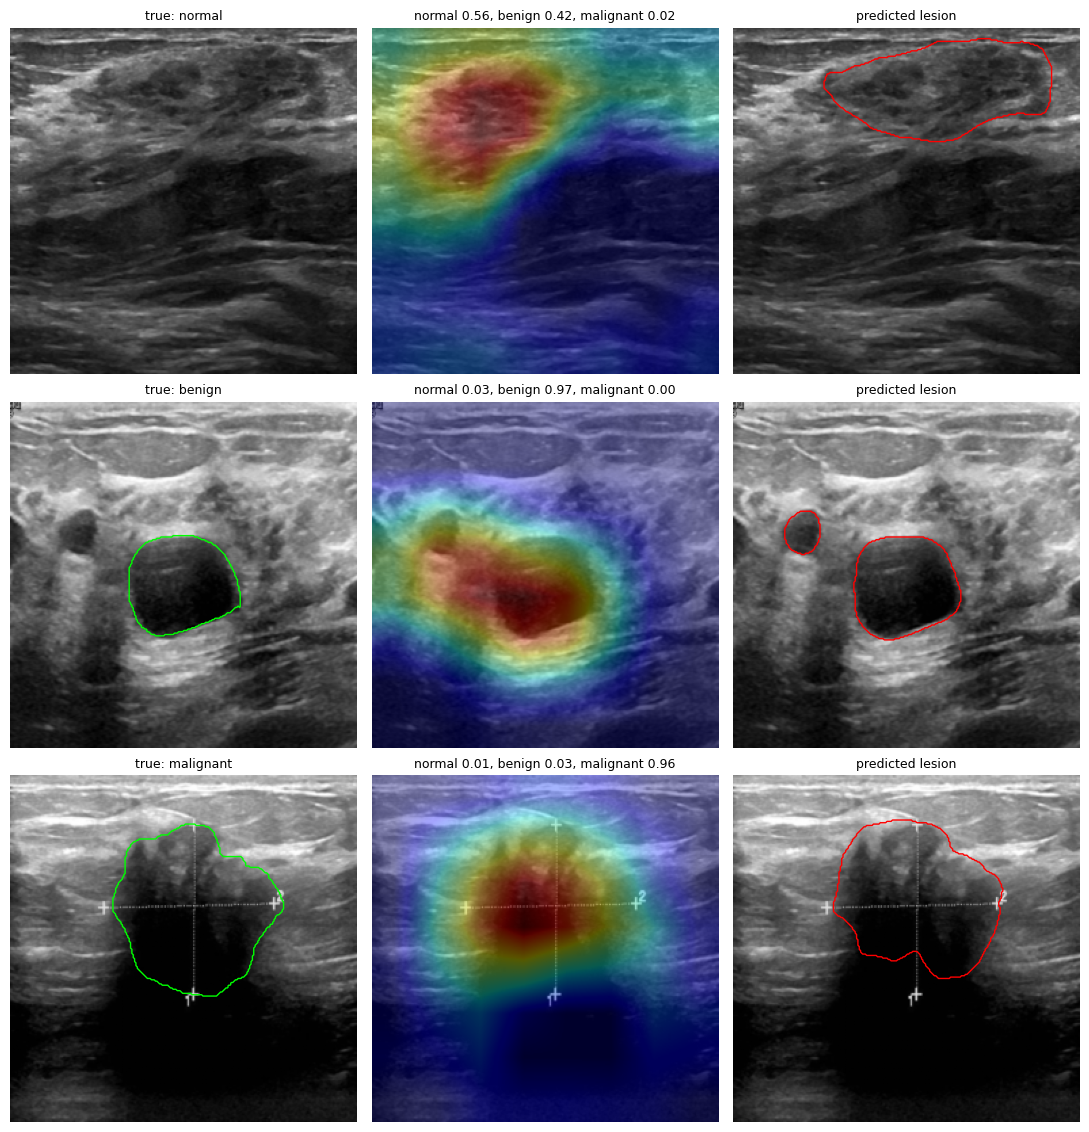

In [20]:
def analyze(img, fold):
    # img = uint8 image already padded and resized to IMG_SIZE
    x = to_input(img)
    classifier, unet = classifiers[fold], unets[fold]
    cam, cls, probs = grad_cam(classifier, x, classifier.layer4)
    unet.eval()
    with torch.no_grad():
        prob = torch.sigmoid(unet(x[None].to(DEVICE)))[0, 0].cpu().numpy()
    return probs, cam, clean_mask(prob > 0.5)


fig, axes = plt.subplots(3, 3, figsize=(11, 11.4))
for k, row in enumerate(axes):
    i = rng.choice(np.flatnonzero(y_all == k))
    probs, cam, pred = analyze(images[i], df.at[i, "fold"])
    show(row[0], images[i], masks[i], title=f"true: {CLASSES[k]}")
    row[1].imshow(images[i], cmap="gray")
    row[1].imshow(cam, cmap="jet", alpha=0.35)
    row[1].set_title(", ".join(f"{c} {p:.2f}" for c, p in zip(CLASSES, probs)), fontsize=9)
    row[1].axis("off")
    show(row[2], images[i], pred=pred, title="predicted lesion" if pred.any() else "no lesion predicted")
plt.tight_layout()
plt.show()

## 8. External test (BUS-BRA)

BUS-BRA is a different hospital, with different machines and patients. It has no normal images, so I only look at benign vs malignant, using the predicted probability of malignant. The scores will probably be lower than on the curated BUSI, and how much lower tells how much the models depend on where the training data came from.

Here the 5 fold models work together: I average their probabilities (and the lesion probabilities of the 5 U-Nets), still with the flip. An ensemble is usually a little better than one model alone, so BUS-BRA gets a small advantage over the out-of-fold column, where each image only goes through one model. The threshold on P(malignant) is the one from section 5, unchanged.

Some patients have several images, so for the confidence interval I resample patients instead of images.

Downloaded from [Zenodo](https://doi.org/10.5281/zenodo.8231412) (134 MB, CC BY 4.0).

In [21]:
BUSBRA_URL = "https://zenodo.org/records/8231412/files/BUSBRA.zip?download=1"
BUSBRA_MD5 = "1f8b2be6476d58fc97bfb5e5a1ea9bab"


def get_busbra():
    if BUSBRA_DIR is not None:
        return next(Path(BUSBRA_DIR).rglob("bus_data.csv")).parent
    root = DATA_DIR / "BUSBRA"
    if not (root / "bus_data.csv").exists():
        download(BUSBRA_URL, BUSBRA_MD5, DATA_DIR / "BUSBRA.zip")   # the zip contains a BUSBRA/ folder
    return root


busbra_root = None
if RUN_EXTERNAL_TEST:
    try:
        busbra_root = get_busbra()
        print(busbra_root)
    except Exception as e:   # no internet, zenodo down, ...
        print("skipping the external test:", e)

downloading BUSBRA.zip...
data/BUSBRA


In [22]:
def lesion_metrics(y, p, scores):
    malignant = y == 2
    pred = p.argmax(1)
    return {
        "ROC-AUC malignant vs benign": roc_auc_score(malignant, p[:, 2]),
        "malignant sensitivity": np.mean(pred[malignant] == 2),
        "benign specificity": np.mean(pred[~malignant] != 2),
        "malignant sensitivity at threshold": np.mean(p[malignant, 2] >= threshold),
        "benign specificity at threshold": np.mean(p[~malignant, 2] < threshold),
        "lesions predicted normal": np.mean(pred == 0),
        "mean Dice": scores[:, 0].mean(),
        "mean IoU": scores[:, 1].mean(),
    }


if busbra_root is not None:
    bb = pd.read_csv(busbra_root / "bus_data.csv")
    bb["y"] = np.where(bb["Pathology"] == "malignant", 2, 1)
    print(len(bb), "images,", bb["Case"].nunique(), "patients")
    print(bb["Pathology"].value_counts().to_string())

    bb_images, bb_masks = [], []
    for id_ in bb["ID"]:
        # bus_0001-l.png -> mask_0001-l.png
        mask_path = busbra_root / "Masks" / (id_.replace("bus", "mask", 1) + ".png")
        img, mask = load_case(busbra_root / "Images" / f"{id_}.png", [mask_path])
        bb_images.append(img)
        bb_masks.append(mask)
    bb_images, bb_masks = np.stack(bb_images), np.stack(bb_masks)
    bb_loader = DataLoader(BreastUltrasound(bb_images, bb_masks, bb["y"].values), batch_size=BATCH_SIZE)

    p_bb, y_bb = predict_probs(classifiers, bb_loader)
    bb_pred = predict_masks(unets, bb_loader)
    bb_scores = np.array([dice_iou(p, g) for p, g in zip(bb_pred, bb_masks)])

    busi = lesion_metrics(y_all[lesion], p_oof[lesion], test_df.loc[lesion, ["dice", "iou"]].values)
    external = pd.DataFrame({
        f"curated BUSI, out of fold ({lesion.sum()} lesions)": busi,
        f"BUS-BRA, {N_FOLDS} models ({len(bb)} lesions)": lesion_metrics(y_bb, p_bb, bb_scores),
    }).round(3)

    lo, hi = bootstrap_ci(lambda y, p: roc_auc_score(y == 2, p[:, 2]), y_bb, p_bb, groups=bb["Case"].values)
    print(f"BUS-BRA ROC-AUC 95% CI (resampling patients): [{lo:.3f}, {hi:.3f}]")
    display(external)

1875 images, 1064 patients
Pathology
benign       1268
malignant     607
BUS-BRA ROC-AUC 95% CI (resampling patients): [0.777, 0.831]


,"curated BUSI, out of fold (386 lesions)","BUS-BRA, 5 models (1875 lesions)"
ROC-AUC malignant vs benign,0.932,0.805
malignant sensitivity,0.823,0.590
benign specificity,0.892,0.845
malignant sensitivity at threshold,0.890,0.812
benign specificity at threshold,0.815,0.634
lesions predicted normal,0.062,0.259
mean Dice,0.738,0.670
mean IoU,0.641,0.583


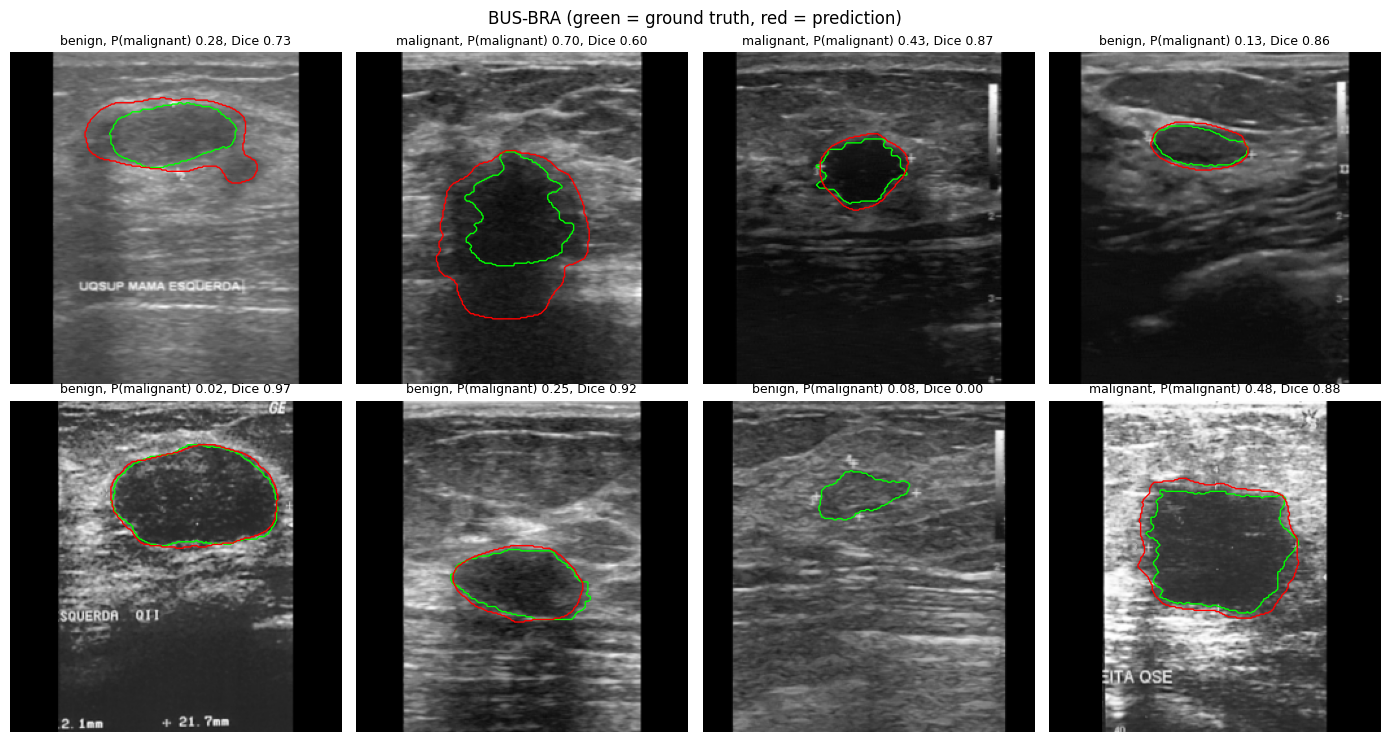

In [23]:
if busbra_root is not None:
    fig, axes = plt.subplots(2, 4, figsize=(14, 7.6))
    for ax, i in zip(axes.flat, rng.choice(len(bb), 8, replace=False)):
        title = f"{bb.at[i, 'Pathology']}, P(malignant) {p_bb[i, 2]:.2f}, Dice {bb_scores[i, 0]:.2f}"
        show(ax, bb_images[i], bb_masks[i], bb_pred[i], title=title)
    plt.suptitle("BUS-BRA (green = ground truth, red = prediction)")
    plt.tight_layout()
    plt.show()

## 9. Summary

In [24]:
print("Classification, curated BUSI, out of fold")
display(cls_results)
print("Segmentation, curated BUSI, out of fold")
display(seg_results)
print(f"normal images with a predicted lesion: {false_alarms}/{(~lesion).sum()}")
if busbra_root is not None:
    print("Lesions only, curated BUSI out of fold vs BUS-BRA")
    display(external)

Classification, curated BUSI, out of fold


,value,95% CI
metric,,
accuracy,0.829,"[0.793, 0.860]"
balanced accuracy,0.843,"[0.808, 0.875]"
macro-F1,0.819,"[0.778, 0.852]"
ROC-AUC (one vs rest),0.939,"[0.918, 0.956]"
malignant sensitivity,0.823,"[0.766, 0.880]"
malignant specificity,0.895,"[0.860, 0.931]"
malignant sensitivity at threshold,0.890,"[0.840, 0.930]"
benign specificity at threshold,0.815,"[0.765, 0.869]"


Segmentation, curated BUSI, out of fold


,n,mean Dice,95% CI,mean IoU
lesions,,,,
benign,222,0.755,"[0.719, 0.788]",0.665
malignant,164,0.714,"[0.672, 0.754]",0.607
all lesions,386,0.738,"[0.711, 0.764]",0.641


normal images with a predicted lesion: 21/64
Lesions only, curated BUSI out of fold vs BUS-BRA


,"curated BUSI, out of fold (386 lesions)","BUS-BRA, 5 models (1875 lesions)"
ROC-AUC malignant vs benign,0.932,0.805
malignant sensitivity,0.823,0.590
benign specificity,0.892,0.845
malignant sensitivity at threshold,0.890,0.812
benign specificity at threshold,0.815,0.634
lesions predicted normal,0.062,0.259
mean Dice,0.738,0.670
mean IoU,0.641,0.583


### Limits

- 450 images is still small, and each fold model trains on about 300 of them. The confidence intervals come from resampling the images, so they don't include how much the results would move with another training run or another split into folds.
- BUSI doesn't give patient IDs, so two images of the same woman can end up in different folds. The closest pairs in the duplicate check (section 3, correlation up to about 0.68, like `benign_id_94` and `benign_id_108`) look like two frames of the same scan.
- All the training data comes from a single hospital (section 8 shows what happens elsewhere).
- Text, measurements or calipers are still drawn on some of the curated images. The CNN could learn those marks instead of the lesion, which is why I look at Grad-CAM.
- The threshold on P(malignant) is set on small validation sets, and one that finds 90% of the cancers on BUSI doesn't have to do the same on another machine.
- Not validated for any clinical use.

### References

- W. Al-Dhabyani, M. Gomaa, H. Khaled, A. Fahmy. *Dataset of breast ultrasound images.* Data in Brief 28, 104863 (2020).
- A. Pawłowska, A. Karwat, N. Żołek. *Letter to the Editor. Re: "Dataset of breast ultrasound images".* Data in Brief 48, 109247 (2023).
- C. Aumente-Maestro, J. Díez, B. Remeseiro. *A multi-task framework for breast cancer segmentation and classification in ultrasound imaging.* Computer Methods and Programs in Biomedicine 260, 108540 (2025).
- C. Aumente-Maestro, J. Díez, B. Remeseiro. *Curated BUSI dataset - Curated Breast Ultrasound Images.* Zenodo, doi:10.5281/zenodo.19047974 (2026).
- W. Gómez-Flores, M. J. Gregorio-Calas, W. C. de Albuquerque Pereira. *BUS-BRA: A breast ultrasound dataset for assessing computer-aided diagnosis systems.* Medical Physics 51(4), 3110-3123 (2024).
- K. He, X. Zhang, S. Ren, J. Sun. *Deep residual learning for image recognition.* CVPR (2016).
- O. Ronneberger, P. Fischer, T. Brox. *U-Net: Convolutional networks for biomedical image segmentation.* MICCAI (2015).
- R. R. Selvaraju et al. *Grad-CAM: Visual explanations from deep networks via gradient-based localization.* ICCV (2017).